In [6]:
import pandas as pd
from matplotlib import pyplot as plt

DPA_HZ = 1.8e9
EUS = 16

d = pd.read_csv("results/live.csv").sort_values(["eu", "t_s"])
dt = d.groupby("eu")["t_s"].diff()
d["pkts"] = d.groupby("eu")["count"].diff() / dt
d["cyc"] = d.groupby("eu")["cycles"].diff() / dt
d = d.dropna()
tot = d.groupby("t_s")[["pkts", "cyc"]].sum()
tot["cycles_per_pkt"] = tot["cyc"] / tot["pkts"]
tot["auslastung"] = tot["cyc"] / (EUS * DPA_HZ)
tot.describe()

,pkts,cyc,cycles_per_pkt,auslastung
count,4.900000e+01,4.900000e+01,49.000000,49.000000
mean,3.905783e+06,2.878675e+10,7370.360131,0.999540
std,2.575566e+04,1.713072e+08,25.652757,0.005948
min,3.757022e+06,2.763037e+10,7314.319756,0.959388
25%,3.906435e+06,2.880048e+10,7358.148569,1.000017
50%,3.912216e+06,2.880734e+10,7362.309646,1.000255
75%,3.915653e+06,2.882104e+10,7371.636567,1.000730
max,3.937157e+06,2.892889e+10,7474.065224,1.004475


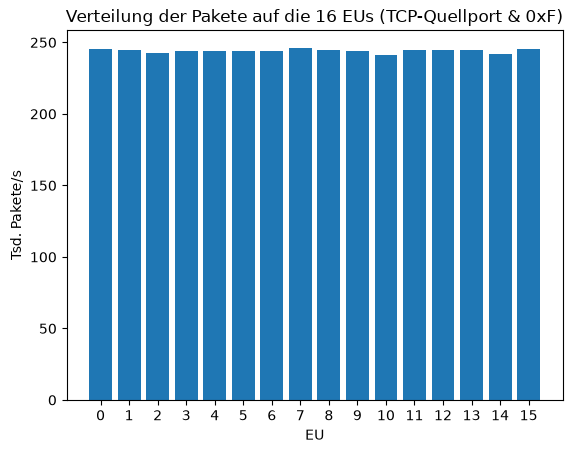

In [7]:
per_eu = d.groupby("eu")["pkts"].mean()
plt.bar(per_eu.index, per_eu / 1e3)
plt.xticks(per_eu.index)
plt.xlabel("EU")
plt.ylabel("Tsd. Pakete/s")
plt.title("Verteilung der Pakete auf die 16 EUs (TCP-Quellport & 0xF)")
plt.show()

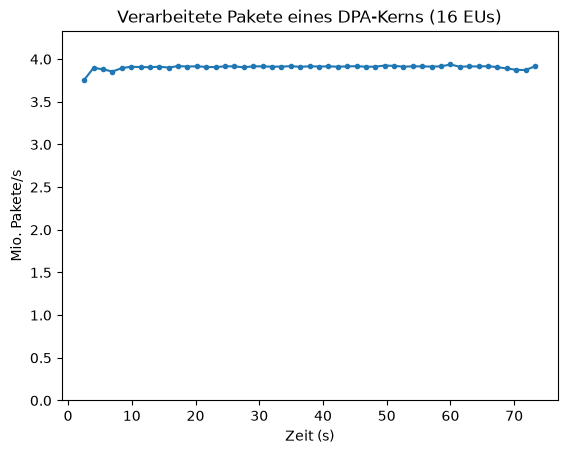

In [10]:
plt.plot(tot.index, tot["pkts"] / 1e6, ".-")
plt.ylim(0, 1.1 * tot["pkts"].max() / 1e6)
plt.xlabel("Zeit (s)")
plt.ylabel("Mio. Pakete/s")
plt.title("Verarbeitete Pakete eines DPA-Kerns (16 EUs)")
plt.show()

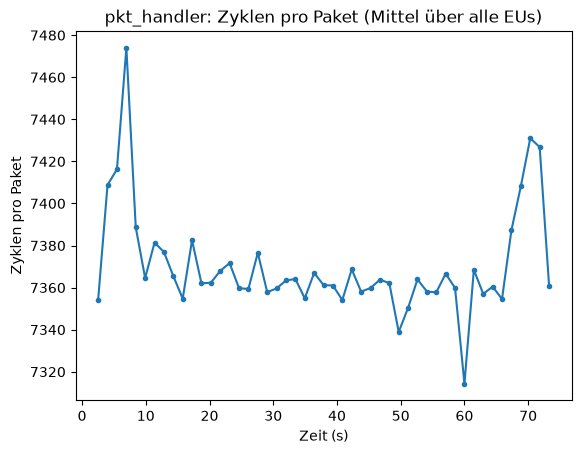

In [ ]:
plt.plot(tot.index, tot["cycles_per_pkt"], ".-")
plt.ylim(0, 1.1 * tot["cycles_per_pkt"].max())
plt.xlabel("Zeit (s)")
plt.ylabel("Zyklen pro Paket")
plt.title("pkt_handler: Zyklen pro Paket (Mittel über alle EUs)")
plt.show()